# Riesz — long-range Active Model B

공통 모델과 수치 프로토콜을 사용하는 독립 실행 노트북. **Run All**로 시뮬레이션, steady-state 진단, EP map, structure factor, phi/source-distance decomposition, profile 영상과 원형 클러스터 / 중앙 wall 안정성 실험을 생성한다.

$\widehat K(q)=(\ell q)^{-\alpha}$, $0<\alpha<2$. 연속 2D의 $K(r)\propto r^{\alpha-2}$에 대응하는 lattice Riesz potential이다.

모든 경우 $\widehat K(0)=0$으로 두어 conserved mean과 무관한 커널을 정의한다. 따라서 표시되는 periodic real-space 커널은 **평균이 0인 signed kernel**이다. 격자 간격은 UV cutoff, box 크기는 IR cutoff이다.

## 모델과 단위

주기적 $64\times64$ 격자에서 mobility $M$인 conserved Active Model B를 적분한다.

$$\partial_t\phi=M\Delta_h(\mu_C+\mu_A)+\sqrt{2MD}\,\nabla_h\!\cdot\Lambda,$$
$$F_C=\Delta V\sum_x\left[\frac a2\phi_x^2+\frac b4\phi_x^4
+\frac\kappa2|\nabla_h\phi_x|^2\right]
+\frac{g\Delta V}{2}\sum_q\widehat K(q)|\widehat\phi_q|^2,$$
$$\mu_C=a\phi+b\phi^3-\kappa\Delta_h\phi+gK*\phi,
\qquad\mu_A=\lambda|\nabla_h\phi|^2.$$

FFT는 orthonormal이다. $\Delta V=\Delta x^2$,
$q^2=4\Delta x^{-2}[\sin^2(k_x\Delta x/2)+\sin^2(k_y\Delta x/2)]$를
Laplacian, 커널, noise covariance 모두에 사용한다. $|\nabla_h\phi|^2$는
각 축의 forward/backward bond gradient 제곱의 평균이다. $D$는 noise temperature,
noise covariance는 $2MD(-\Delta_h)/\Delta V$이다. $g>0$는 해당 density mode를 억제한다.

적분은 모든 drift를 현재 field에서 평가하는 **Euler–Maruyama**를 사용한다.
$$\widehat\phi_q^{n+1}=\widehat\phi_q^n
-M q^2\widehat\mu_q(\phi^n)\,dt
+\sqrt{2MD\,dt/\Delta V}\,q\,\widehat\xi_q^n.$$
Fourier zero mode를 고정하여 질량을 보존한다. 기본 $dt=0.01$이고, EP는 아래의 midpoint를
사용한다. 정량 비교에는 같은 물리 시간에서 $dt,dt/2$ 수렴 확인이 필요하다.


In [1]:
from pathlib import Path
import sys
import json
from dataclasses import asdict, replace
from hashlib import sha256

# Supports opening from LRAMB itself or a parent directory.
ROOT = Path.cwd()
if not (ROOT / 'lramb').is_dir():
    ROOT = next((p for p in [ROOT / 'LRAMB', *ROOT.parents] if (p / 'lramb').is_dir()), ROOT)
if not (ROOT / 'lramb').is_dir():
    raise FileNotFoundError('Open this notebook from the LRAMB repository or install it with pip install -e .')
sys.path.insert(0, str(ROOT))

import numpy as np
import matplotlib.pyplot as plt
from IPython.display import HTML, Image, display
from lramb import Parameters, KernelSpec, ActiveModelB, Run, simulate, backend_options
from lramb.analysis import stationarity_report, block_summary
from lramb.decomposition import KernelDecomposition, DecompositionResult
from lramb.circle import (CircleSpec, circle_initial, run_circle_pair,
    circle_diagnostics, save_circle_report)
from lramb.plotting import (plot_kernel, plot_diagnostics, plot_ep_maps,
    plot_structure, profile_animation, plot_kernel_decomposition, plot_circle_stability)

plt.rcParams.update({'figure.dpi': 105, 'font.size': 10, 'animation.embed_limit': 60})


## 1. 파라미터와 교체 가능한 interaction

`strength=0`이면 local Active Model B baseline, `lam=0`이면 passive Model B이다. `CUSTOM_MULTIPLIER`에 `(n,n)`의 real inversion-symmetric 배열 또는 `f(qx,qy)` 함수를 넣으면 사용자 커널을 적용한다. `strength`는 그 multiplier에 곱해진다. 음의 strength도 가능하지만 안정성은 별도로 살펴야 한다. 양의 strength에서도 coarsening이 지속될 수 있으므로 burn-in을 steady state로 간주하지 않는다.

In [2]:
KIND = 'riesz'
p = Parameters(n=64, dx=1.0, dt=0.01, a=-1.0, b=1.0, kappa=1.0,
               lam=0.8, mobility=1.0, D=0.05, mean=-0.2, seed=17)
kernel = KernelSpec(kind=KIND, strength=0.35, ell=2.0, alpha=1.0)
CUSTOM_MULTIPLIER = None
# Example: CUSTOM_MULTIPLIER = lambda qx, qy: 1/(1 + 4*qx**2 + qy**2)
model = ActiveModelB(p, kernel, multiplier=CUSTOM_MULTIPLIER)

INITIAL_MODE = 'random'  # random / stripe; stripe reduces two-phase coarsening transients
BURN_STEPS = 40_000
PRODUCTION_STEPS = 64_000
SAMPLE_EVERY = 40       # interval entropy rates: delta_t = 0.4
FRAME_EVERY = 200       # fields/structure snapshots: delta_t = 2
BLOCKS = 8             # production_steps divisible by sample_every * blocks
DECOMP_PHI_EDGES = np.linspace(-2, 2, 33)
DECOMP_DISTANCE_SHELLS = 12  # includes an isolated on-site rho=0 shell
SIMULATION = backend_options('auto', device='auto', dtype='float64')
# auto: CUDA available -> torch/CUDA; otherwise NumPy. 'torch' also enables torch CPU.
REUSE_CACHE = True      # cache only reused when parameters, source and multiplier match
SAVE_VIDEO = True
OUTPUT = ROOT / 'results' / KIND
OUTPUT.mkdir(parents=True, exist_ok=True)
print(f'{p.n} x {p.n}, burn={BURN_STEPS*p.dt:g}, production={PRODUCTION_STEPS*p.dt:g}')
print(f'EP sample interval={SAMPLE_EVERY*p.dt:g}; Nyquist={1/(2*SAMPLE_EVERY*p.dt):g}')
display(asdict(p), asdict(kernel))
print('Simulation backend:', SIMULATION)


64 x 64, burn=400, production=640
EP sample interval=0.4; Nyquist=1.25


{'n': 64,
 'dx': 1.0,
 'dt': 0.01,
 'a': -1.0,
 'b': 1.0,
 'kappa': 1.0,
 'lam': 0.8,
 'mobility': 1.0,
 'D': 0.05,
 'mean': -0.2,
 'seed': 17}

{'kind': 'riesz', 'strength': 0.35, 'ell': 2.0, 'alpha': 1.0}

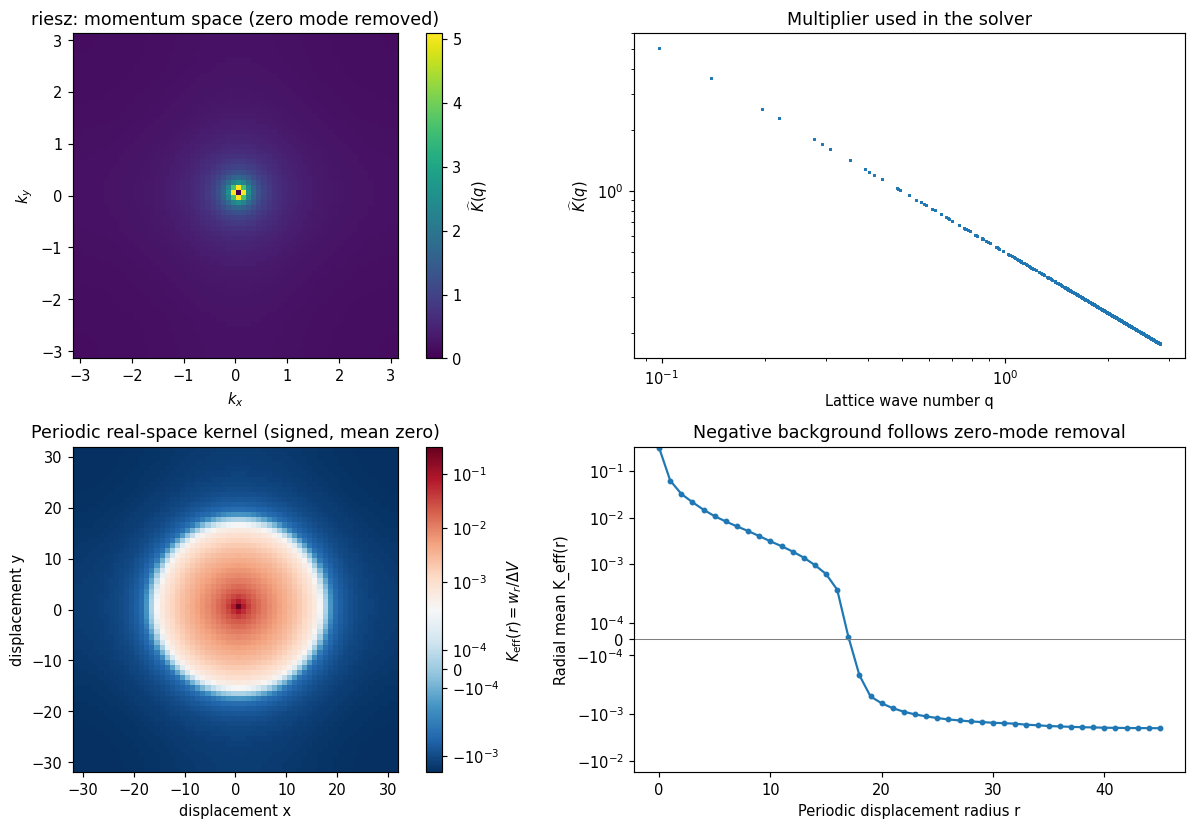

In [3]:
fig_kernel = plot_kernel(model, OUTPUT)
plt.show()

## 2. 64 × 64 시뮬레이션

EP map과 active entropy는 모든 integration step에서 누적한다. convolution의 source-distance shell과 receiving phi bin별 EP도 매 step에서 누적한다. 따라서 PSD는 `SAMPLE_EVERY * dt` 구간 평균 rate의 스펙트럼이며 그보다 빠른 fluctuation은 분해하지 못한다. 고주파를 보려면 `SAMPLE_EVERY`를 줄인다. 캐시는 코드와 파라미터가 일치할 때만 재사용된다.

In [4]:
observer = KernelDecomposition(model, phi_edges=DECOMP_PHI_EDGES,
                               shells=DECOMP_DISTANCE_SHELLS)
source_hash = sha256(b''.join((ROOT/'lramb'/f).read_bytes()
    for f in ['model.py', 'decomposition.py', 'backends.py', 'torch_backend.py'])).hexdigest()
signature = sha256(json.dumps({
    'p': asdict(p), 'kernel': asdict(kernel), 'initial': INITIAL_MODE,
    'burn': BURN_STEPS, 'production': PRODUCTION_STEPS,
    'sample': SAMPLE_EVERY, 'frame': FRAME_EVERY, 'blocks': BLOCKS,
    'simulation': SIMULATION,
    'source': source_hash, 'multiplier': sha256(model.K.tobytes()).hexdigest(),
    'phi_edges': observer.phi_edges.tolist(), 'distance_edges': observer.distance_edges.tolist(),
}, sort_keys=True).encode()).hexdigest()
cache = OUTPUT / 'trajectory.npz'
decomp_cache = OUTPUT / 'phi_distance_decomposition.npz'
run = Run.load(cache) if REUSE_CACHE and cache.exists() else None
decomp = DecompositionResult.load(decomp_cache) if REUSE_CACHE and decomp_cache.exists() else None
if (run is None or run.metadata.get('signature') != signature or
    decomp is None or decomp.metadata.get('signature') != signature):
    run = simulate(model, burn_steps=BURN_STEPS, production_steps=PRODUCTION_STEPS,
                   sample_every=SAMPLE_EVERY, frame_every=FRAME_EVERY, blocks=BLOCKS,
                   initial=model.initial_field(INITIAL_MODE), progress=True, decomposition=observer, **SIMULATION)
    decomp = observer.result
    run.metadata['signature'] = signature
    run.metadata['initial_mode'] = INITIAL_MODE
    decomp.metadata['signature'] = signature
    run.save(cache)
    decomp.save(decomp_cache)
    print('Saved', cache)
else:
    print('Loaded matching cache:', cache)

print('Max mass drift:', np.max(np.abs(run.mass - run.mass[0])))
print('Max conservative midpoint quadrature residual:', run.balance_error)
print('Max mu_K - sum_rho mu_K,rho residual:', decomp.metadata['max_mu_residual'])
print('Receiving-phi tail fraction:', decomp.metadata['phi_tail_fraction'])
print('Max sum_(phi,rho) EP - total LR EP residual:',
      np.max(np.abs(decomp.rate_lr.sum(axis=(1,2)) - run.ep_rate[:,1])))
ep_atol = 1e-8 if run.metadata.get('dtype','float64') == 'float64' else 1e-2
np.testing.assert_allclose(decomp.rate_lr.sum(axis=(1,2)), run.ep_rate[:,1], atol=ep_atol)
np.testing.assert_allclose(decomp.rate_local.sum(axis=1), run.ep_rate[:,[0,2]], atol=1e-8)


Saved C:\Users\ldh04\OneDrive\문서\CANONEQal\repos\LRAMB\results\riesz\trajectory.npz
Max mass drift: 2.7755575615628914e-17
Max conservative midpoint quadrature residual: 2.2554380221596215
Max mu_K - sum_rho mu_K,rho residual: 4.718447854656915e-16
Receiving-phi tail fraction: 0.0
Max sum_(phi,rho) EP - total LR EP residual: 7.958078640513122e-13


C:\Users\ldh04\AppData\Local\Programs\Python\Python312\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
riesz 64x64: 100%|██████████| 104000/104000 [10:26<00:00, 165.89step/s]


## 3. Steady-state numerics

질량 보존, 자유에너지, field variance, characteristic wave number, block EP, block 길이에 따른 SE를 확인한다. 아래 표의 `drift_detected`는 8개 block 평균에 대한 선형 slope의 95% CI가 0을 포함하지 않는다는 뜻이다. 독립 block 가정을 확인해야 한다. 드리프트가 남거나 structure factor의 production quarter가 겹치지 않으면 `BURN_STEPS`와 `PRODUCTION_STEPS`를 늘려 다시 실행한다. no drift detected는 steady state의 증명이 아니다.

observable,mean,block_se,drift,drift_ci95,drift_detected
F_C / area,-0.007583,6.7994e-05,-7.1144e-05,0.00054439,False
Var(phi),0.16141,0.00068313,-0.00092002,0.0054388,False
mean q (S-weighted),0.63413,0.00090817,-0.0021155,0.0070218,False
active EP / area,0.091211,0.00030213,-0.00072625,0.0023292,False


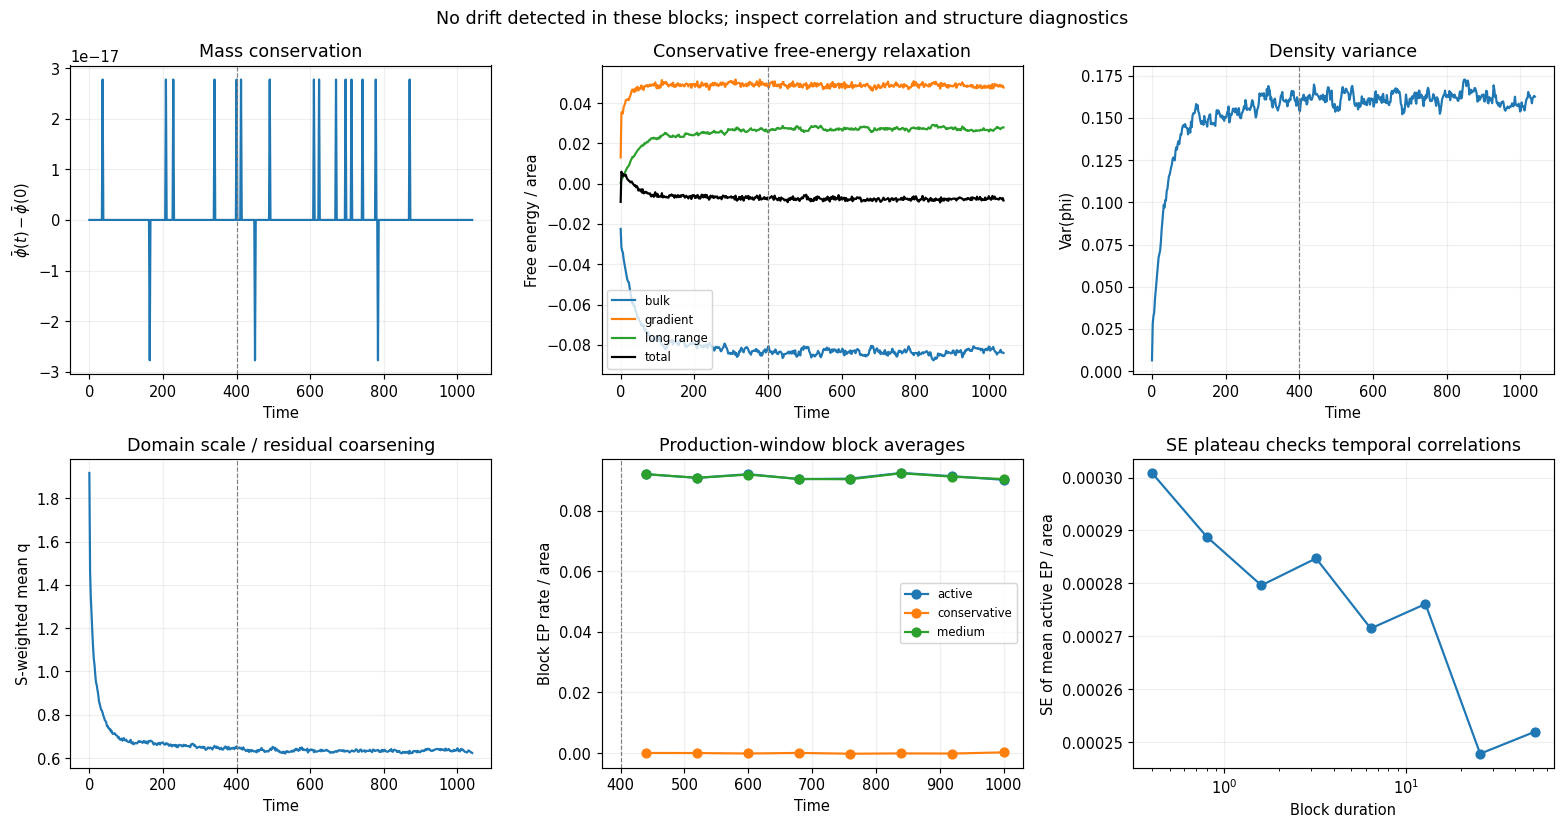

In [5]:
report = stationarity_report(model, run)
headers = ['observable', 'mean', 'block_se', 'drift', 'drift_ci95', 'drift_detected']
body = ''.join('<tr>' + ''.join(f'<td>{row[h]:.5g}</td>' if isinstance(row[h], float)
    else f'<td>{row[h]}</td>' for h in headers) + '</tr>' for row in report)
display(HTML('<table><tr>' + ''.join(f'<th>{h}</th>' for h in headers) + '</tr>' + body + '</table>'))
(OUTPUT/'stationarity.json').write_text(json.dumps(report, indent=2), encoding='utf-8')
fig_diagnostics = plot_diagnostics(model, run, OUTPUT)
plt.show()


## 4. Profile 영상

density map, 중앙 row의 profile, y 방향 평균 profile을 함께 보여준다. 아래 영상은 inline GIF로 재생되며 `profile.gif`도 저장한다. 영상은 최대 100 프레임을 골라 표시하고 통계에는 전체 적분 단계를 사용한다.

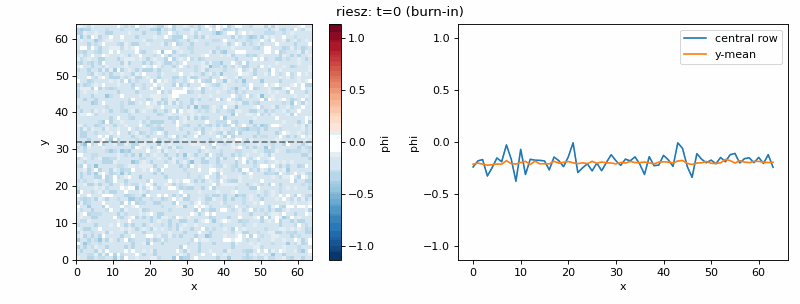

In [6]:
animation = profile_animation(model, run,
    path=OUTPUT/'profile.gif' if SAVE_VIDEO else None, max_frames=100, fps=15)
if SAVE_VIDEO:
    display(Image(filename=str(OUTPUT/'profile.gif')))
else:
    display(HTML(animation.to_jshtml()))


## 5. Chemical-potential 기준 kernel decomposition

이 모델에서 관측하는 **field-level medium entropy**의 convention은

$$dS_{\rm med}=-D^{-1}\Delta V\sum_x(\mu_C+\mu_A)\circ d\phi_x
=-dF_C/D+dS_A,$$
$$dS_A=-D^{-1}\Delta V\sum_x\lambda|\nabla_h\phi|^2\circ d\phi_x.$$

$$\mu_C(x)=\underbrace{a\phi(x)+b\phi(x)^3-\kappa\Delta_h\phi(x)}_{\mu_{C,\mathrm{local}}(x)}
+\underbrace{g\sum_y w_{x-y}\phi(y)}_{\mu_K(x)},\qquad
\mu_K(x)=\sum_\rho\mu_{K,\rho}(x),$$
$$\mu_{K,\rho}(x)=g\sum_{y:\,|x-y|_{\rm periodic}\in B_\rho}w_{x-y}\phi(y).$$

$\rho$는 **커널 중심 $x$에서 source $y$까지의 거리 $|x-y|$**이다.
$\phi$ bin은 **관측점의 midpoint field $\phi_m(x)$**를 사용한다.
$w=\mathrm{IFFT}(\widehat K)$는 cell volume을 포함하는 convolution weight이다.
$\rho=0$ self weight도 포함하고 $\widehat K(0)=0$ gauge를 유지한다.
활동항 $\mu_A=\lambda|\nabla_h\phi|^2$는 local 채널이다.

EP는 모든 항에 같은 midpoint field $\phi_m=(\phi^{n+1}+\phi^n)/2$를 사용한다.
$$\Delta s_\mathrm{med}(x)=-\frac{\mu_C(\phi_m)(x)+\mu_A(\phi_m)(x)}{D}
\,[\phi^{n+1}(x)-\phi^n(x)].$$
quadratic 커널 항에서는 이 midpoint가 $-\Delta F_K/D$와 정확히 일치한다.
quartic bulk 항에는 유한한 quadrature residual이 남으므로, 출력의 conservative balance residual을
반올림 오차로 해석하지 않는다. 각 step의 그 residual은
$b\Delta V\sum_x\phi_m(x)[\Delta\phi(x)]^3/(4D)$이다.
물리적 Stratonovich EP는 $dt\to0$ 극한으로 해석한다.

실제로 누적하는 분해는
$$\Delta s_{K,\rho}(x)=-\mu_{K,\rho}(\phi_m)(x)\Delta\phi(x)/D,$$
$$J_{b\rho}(t_j)=\frac{\Delta V}{\delta t}
\sum_{n\in j,x}\mathbf1[\phi_m(x)\in b]\,\Delta s_{K,\rho}(x).$$
$\mu$에서 EP로 갈 때 별도의 $1/2$ 계수를 넣지 않는다.
$\sum_{b,\rho}J_{b\rho}=\dot S_K$이며 local conservative/active 채널도 같은 $\phi$ bin에 누적한다.
**모든 solver step**을 사용하고 coarse 저장 frame 차분을 사용하지 않는다.

조건부 평균 $\langle\mu_{K,\rho}\mid\phi\rangle$, 점유 site당 조건부 EP와
전체 공간에 대한 additive bin 기여를 구분해서 표시한다. 조건부 평균은 occupancy로 가중해야
전체 값이 된다. 바깥 $\phi$ bin은 tail도 포함하며 tail fraction을 출력한다.

평균 $J(\phi,\rho)$, RMS fluctuation과 Welch $P(\phi,\rho,f)$를 본다.
각 bin의 상관을 유지하도록 전체 PSD는 **rate를 먼저 합산한 뒤** 계산한다.
정상상태에서도 $\phi$별 signed EP는 0일 필요가 없고, $\phi$를 모두 합친 보존적 커널의
장시간 평균이 boundary term으로 사라진다. 국소 EP는 chemical-potential convention을 따른다.


local conservative  : +4.48841e-05 +/- 0.000194 (block SE; per area)
LR conservative     : -7.82395e-05 +/- 0.000165 (block SE; per area)
local active        : +0.0912108 +/- 0.000302 (block SE; per area)
Medium mean EP / area: 0.0911773951193807
Conservative mean from endpoint boundary: 4.740436308708494e-05


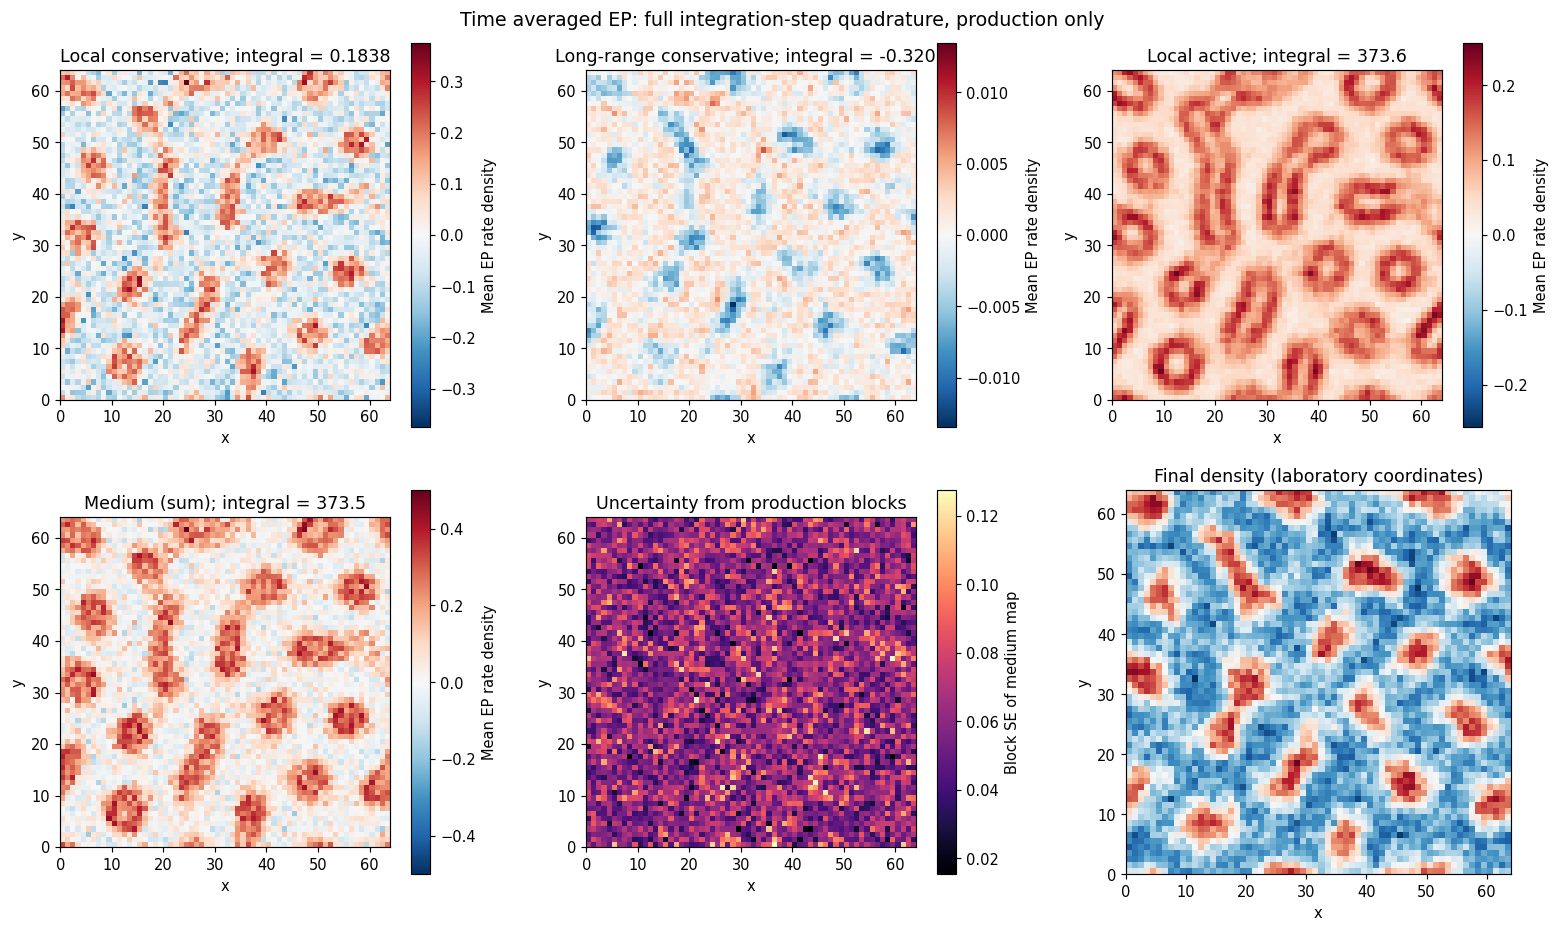

In [7]:
ep_mean, ep_se, _ = block_summary(run.ep_rate, BLOCKS)
for label, value, error in zip(['local conservative', 'LR conservative', 'local active'], ep_mean, ep_se):
    print(f'{label:20s}: {value/model.area:+.6g} +/- {error/model.area:.3g} (block SE; per area)')
print('Medium mean EP / area:', ep_mean.sum()/model.area)
print('Conservative mean from endpoint boundary:',
      -(run.energy[-1].sum() - run.energy[run.time == BURN_STEPS*p.dt][0].sum())
      /(p.D * PRODUCTION_STEPS*p.dt * model.area))
fig_ep = plot_ep_maps(model, run, OUTPUT)
plt.show()


## 6. Structure factor 변화

$S(q,t)=\Delta V|\widehat{\phi-\bar\phi}_q|^2$를 mode당 평균한다. radial curve, 시간 heatmap, production 평균 2D spectrum, production quarter 비교를 출력한다. 파수 shell의 mode 수를 곱해야 integrated spectral weight가 된다.

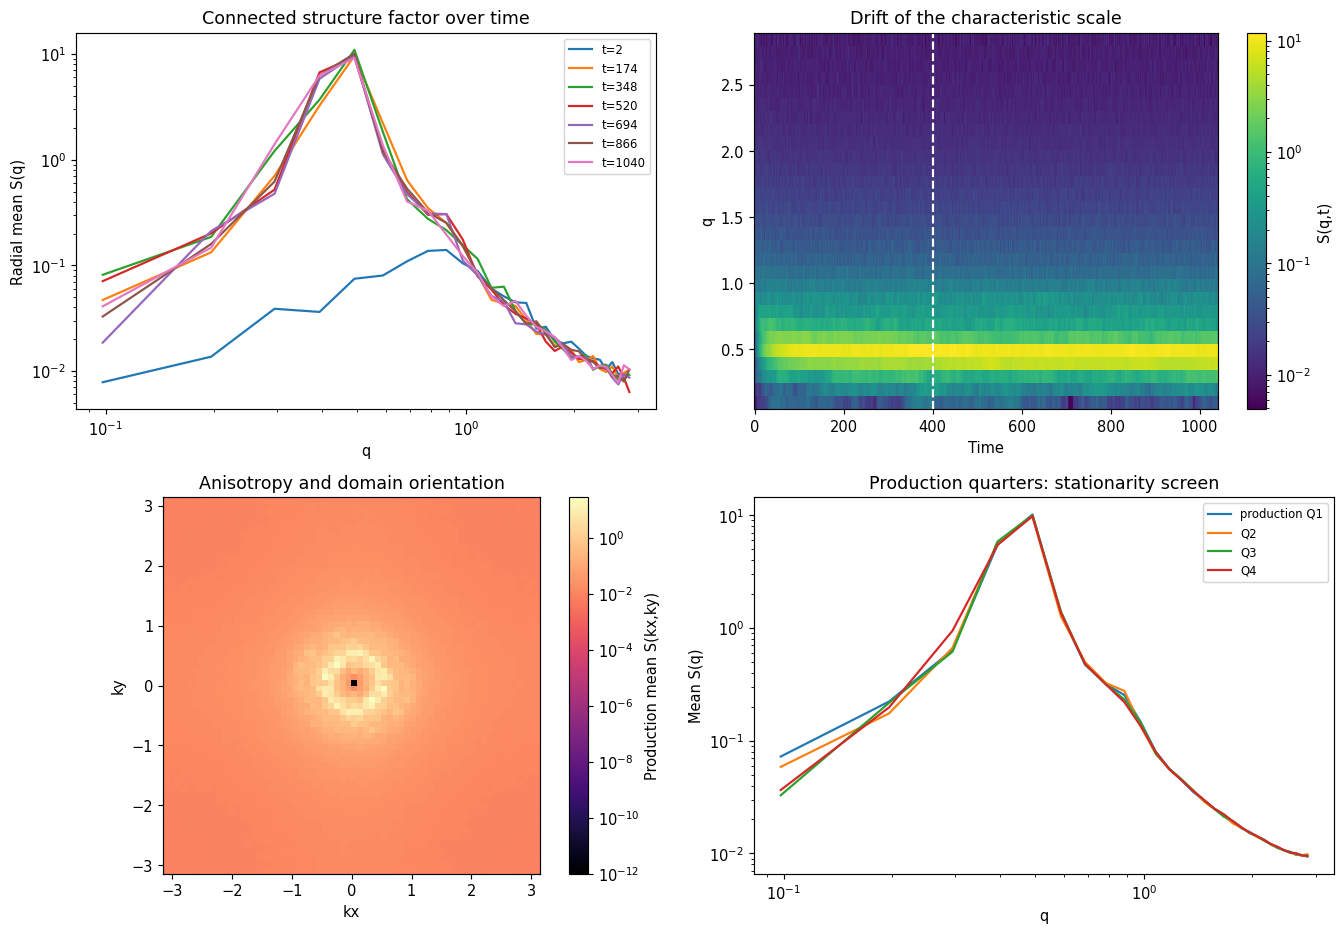

In [8]:
fig_structure = plot_structure(model, run, OUTPUT)
plt.show()

## 7. Receiving phi × source distance kernel decomposition

$\mu_C=\mu_{C,local}+\sum_\rho\mu_{K,\rho}$와 $J(\phi,\rho)$를 출력한다. $\rho=|x-y|$는 source displacement이다. 세 그림은 조건부 chemical potential/EP, additive EP 평균·RMS·주파수 스펙트럼, 선택한 receiving phi에서의 joint PSD를 보여준다. 각 시간 구간은 full-step EP의 합이다.

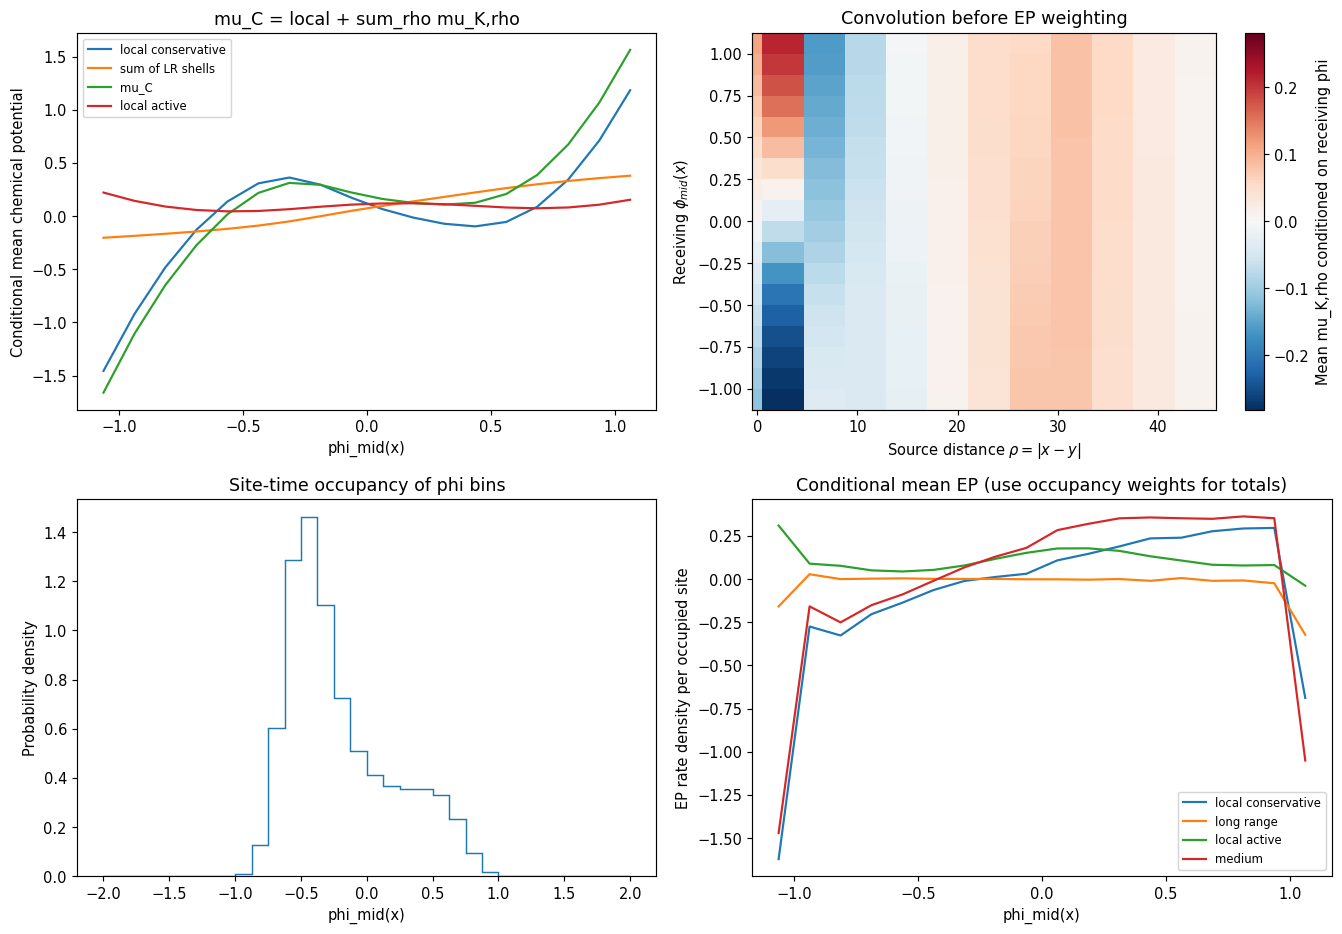

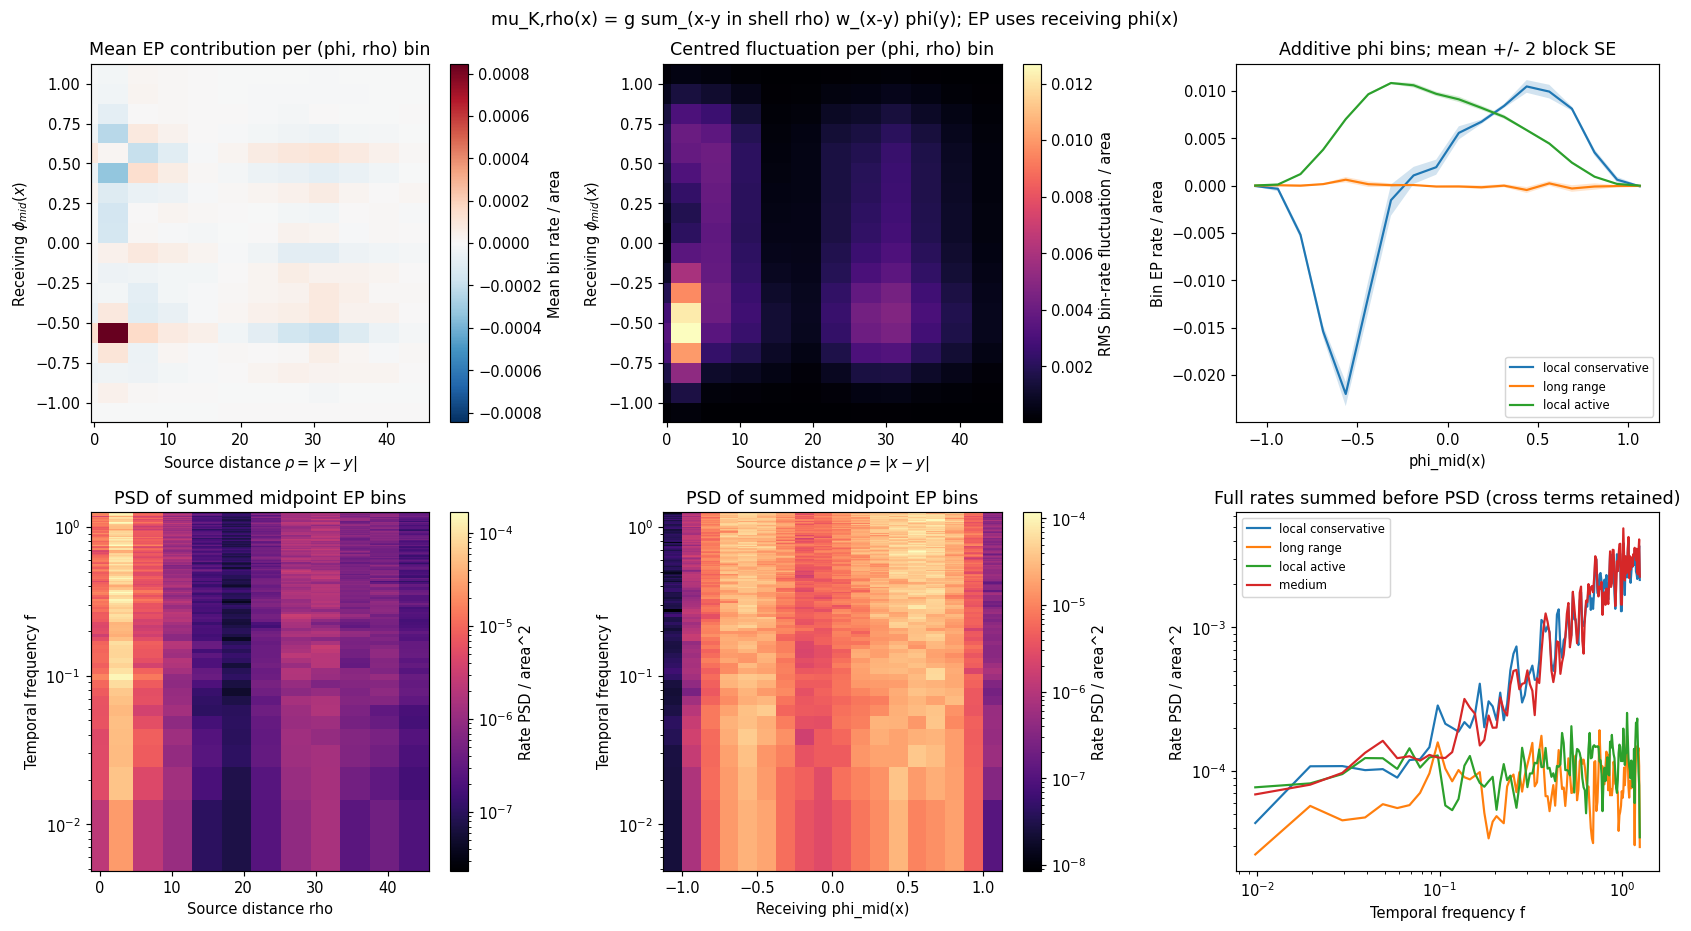

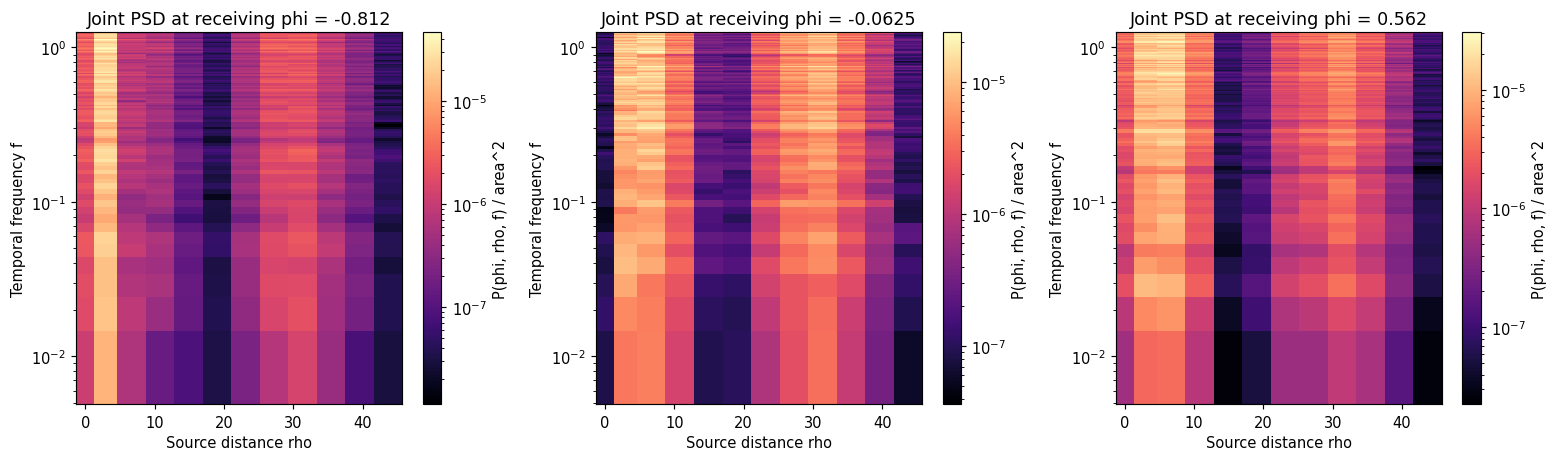

In [9]:
fig_mu, fig_spectrum, fig_phi_psd = plot_kernel_decomposition(decomp, OUTPUT)
plt.show()

## 7b. 같은 rho의 EP를 전부 합한 뒤 variation

각 source-distance shell의 receiving phi bin과 모든 위치의 signed EP를 먼저 합산한다.
Local conservative/active 기여는 rho=0에 넣어 전체 medium EP를 복원한다.
이 한 개의 시간 신호에 대해 Std/Variance와 PSD를 계산하고 rho에 따라 줄어드는지 본다.
아래 그래프는 앞에서 설정한 source-distance shell을 사용한다.
별도 `riesz_ep.ipynb`, `poisson_ep.ipynb`, `linnik_ep.ipynb`는 더 세밀한 dx 폭의 rho shell과
분석을 수행한다. Poisson/Linnik EP 노트북은 kernel.ell을 바꾸며 각 ell에서 새 trajectory를
적분하여 실제 interaction range에 따른 fluctuation을 비교한다. Riesz EP 노트북은
단일 kernel에서 source 거리 rho와 보조적인 누적 거리 cutoff R을 분석한다.
아래에는 fine dx shell의 Var(EP)/rho²와 connected density 2-point C(rho)의
scaling 비교도 포함한다. C의 부호 변화 전의 공통 거리 구간에서 slope를 비교한다.


{'rho_min': 2.55703790890632,
 'rho_max': 14.899265362344241,
 'log_std_slope': -1.5991282281860995,
 'log_std_slope_ci95': [-1.6160939314568892, -1.5827518785906558],
 'spearman_rho': -1.0,
 'decreasing_adjacent_fraction': 1.0,
 'interpretation': 'decreasing over this rho window'}

rho=0 Std (local + on-site K): 180.1209605970822
Whole medium EP Std: 176.56109880179412


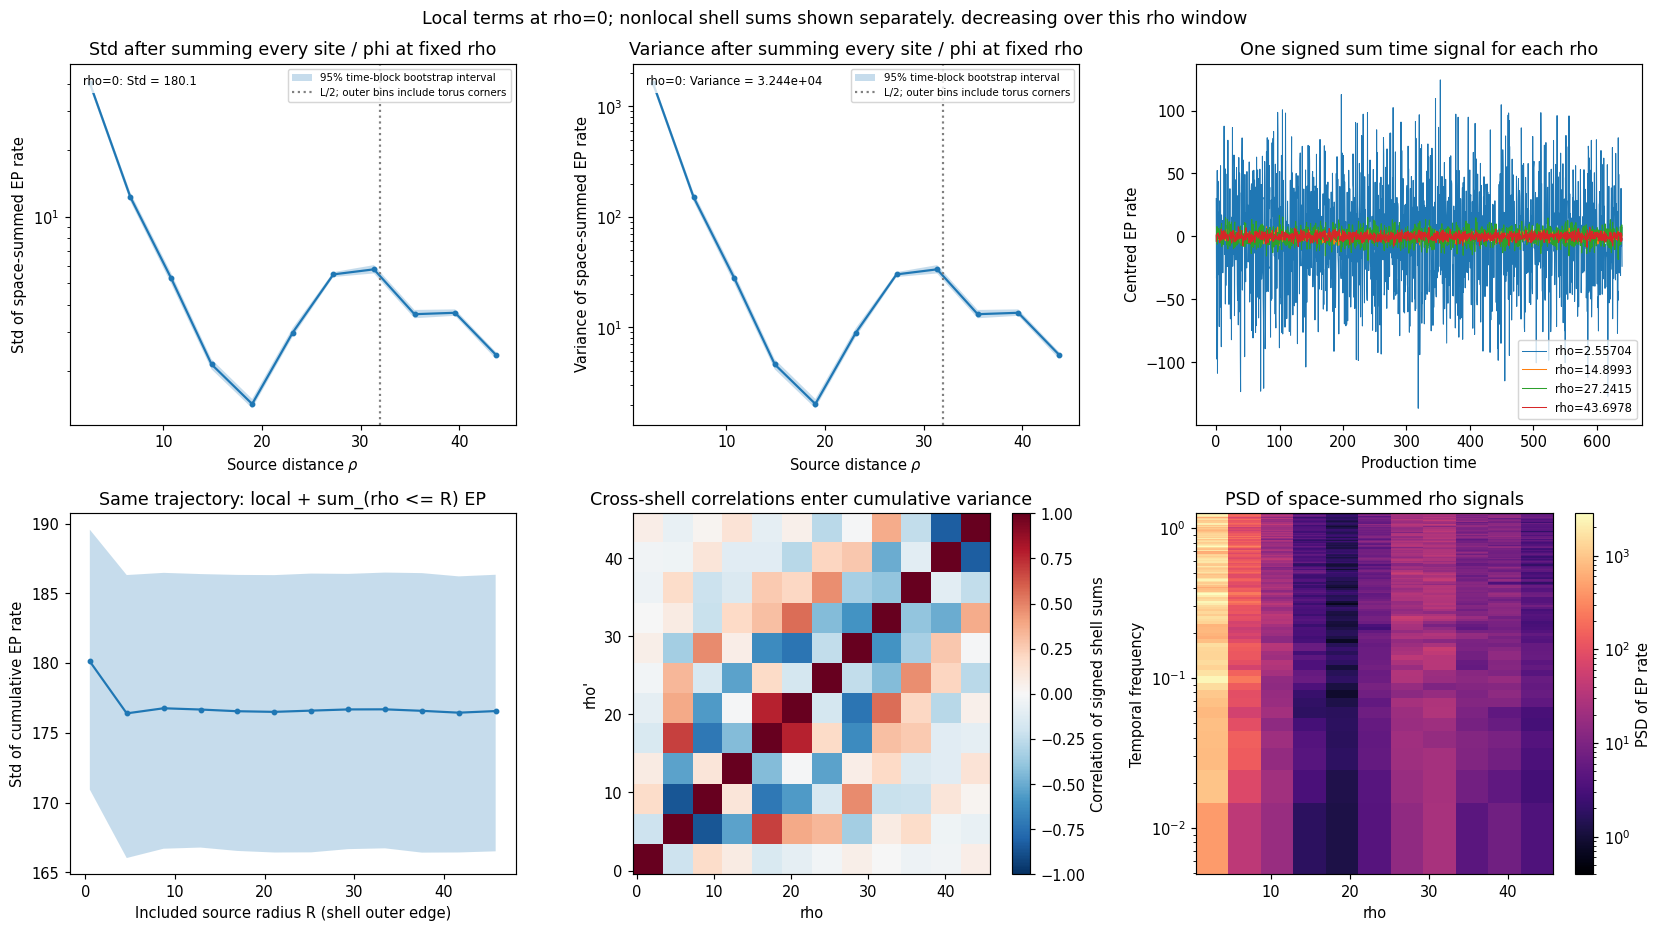

{'requested_window': [2.0, 16.0],
 'ep_full_window': {'rho': [2.0,
   3.0,
   4.0,
   5.0,
   6.0,
   7.0,
   8.0,
   9.0,
   10.0,
   11.0,
   12.0,
   13.0,
   14.0,
   15.0,
   16.0],
  'ep_variance_over_rho2_slope': -5.000011684881596,
  'ep_slope_ci95': [-5.040331423031983, -4.961730368684299],
  'two_point_abs_slope': nan,
  'slope_difference': nan},
 'common_sign_branch': {'rho': [2.0, 3.0, 4.0],
  'ep_variance_over_rho2_slope': -3.8547792483557908,
  'ep_slope_ci95': [-3.9468553064773166, -3.718709249561981],
  'two_point_abs_slope': -1.722751480729607,
  'slope_difference': -2.132027767626184},
 'ep_sampling_interval': 0.4,
 'correlation_sampling': 'every saved production EP endpoint',
 'correlation_uncertainty': 'not estimated: blockwise structure powers were not saved',
 'interpretation': 'descriptive finite-window slopes; not established asymptotic exponents'}

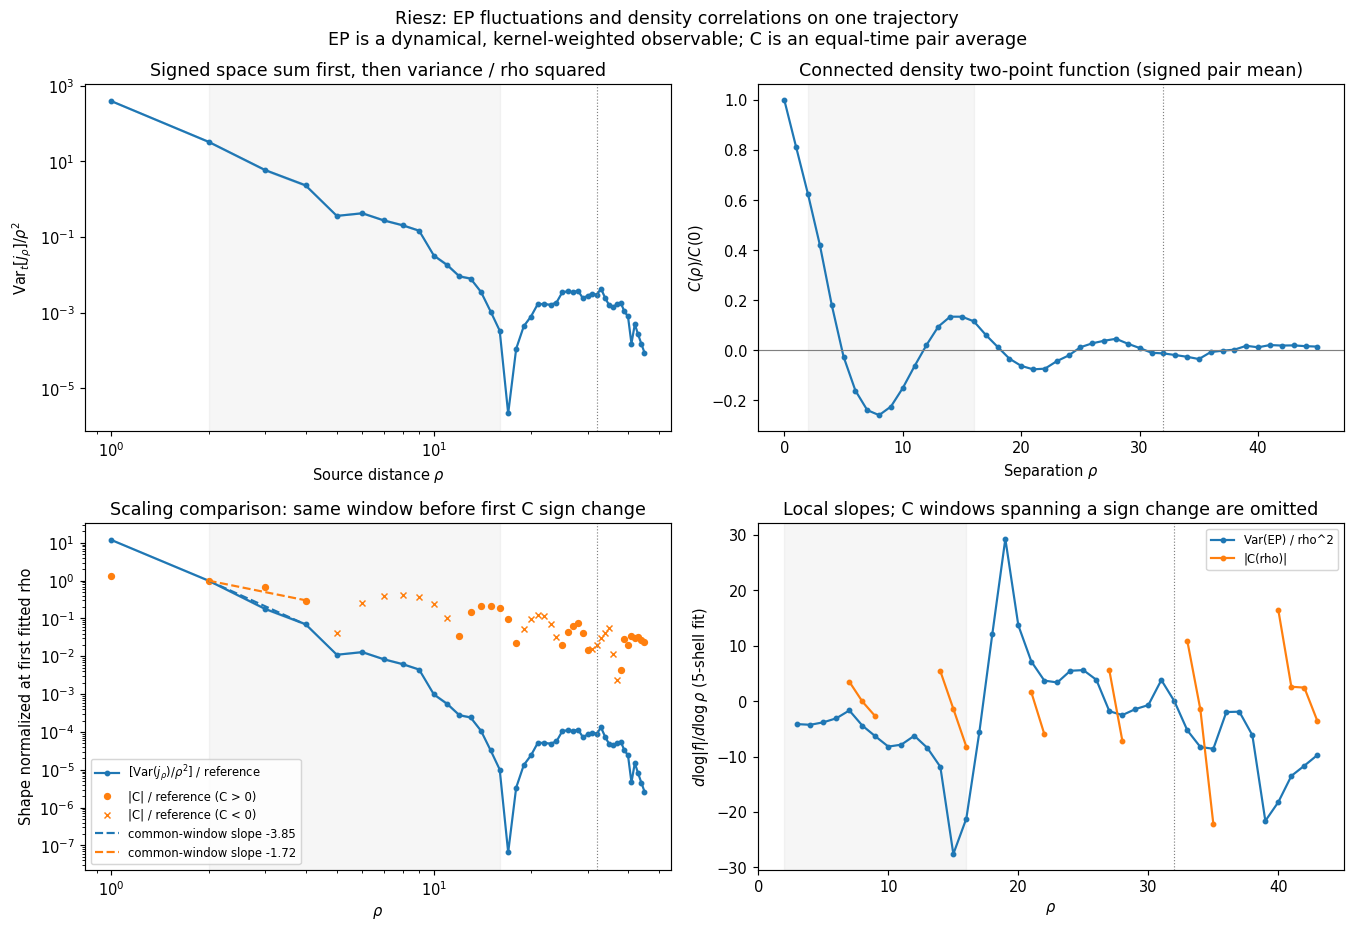

In [2]:
from lramb.ep_ranges import ShellEP, shell_summary, plot_shell_summary
rho_series = ShellEP.from_decomposition(decomp)
rho_summary = shell_summary(rho_series, blocks=BLOCKS, density=False)
ep_atol = 1e-8 if run.metadata.get('dtype','float64') == 'float64' else 1e-2
np.testing.assert_allclose(rho_series.medium_rate.sum(axis=1), run.ep_rate.sum(axis=1), atol=ep_atol)
fig_rho, rho_trend = plot_shell_summary(rho_series, rho_summary, OUTPUT,
    rho_min=2.0, rho_max=16.0, prefix='rho_space_sum_ep')
display(rho_trend)
print('rho=0 Std (local + on-site K):', rho_summary['shell']['std'][0])
print('Whole medium EP Std:', rho_summary['cumulative']['std'][-1])
plt.show()

from lramb.scaling import plot_scaling_comparison
scaling_series=ShellEP.from_run(run)
scaling_summary=shell_summary(scaling_series,blocks=BLOCKS,density=False)
fig_scaling,scaling=plot_scaling_comparison(run,scaling_series,scaling_summary,OUTPUT,
    rho_min=2.0,rho_max=16.0)
display(scaling['report'])
plt.show()


## 8. 원형 클러스터의 finite-time stability

Local bulk free energy $f=a\phi^2/2+b\phi^4/4$의 최소점 $\phi_\pm=\pm\sqrt{-a/b}$로
초기 plateau를 설정한다. 기본 a=-1,b=1에서는 **내부 +1, 외부 -1**이다.
`CircleSpec.from_bulk`는 passive planar tanh width $\sqrt{2\kappa/(-a)}$도 설정한다.
초기 내부 0.8을 사용하던 결과는 이 section에서 재사용하지 않는다.

같은 보존적 noise로 원형 reference와 $R(\theta)=R_b[1+\epsilon\cos(m\theta)]$를 적분한다.
**변형 쌍의 질량은 R_b를 root solve하여 맞춘다. Field 전체를 shift하지 않는다.**
반지름 10과 큰 클러스터 16을 각각 비교하며, 각 반지름/plateau가 만드는 mean을 보존한다.
Local passive (lambda=g=0), local active (g=0, lambda 유지), 현재 active+kernel을 명시적으로
비교한다. 실제 active+kernel 모델의 파라미터는 유지한다. ±1은 local bulk 최소점이며
활동항·long range·곡률까지 포함한 최종 공존 밀도라고 가정하지 않는다.
적분은 Euler–Maruyama, EP는 midpoint이다.

- 주기 경계에서 연결된 positive-phase component의 면적과 $R_A=\sqrt{A/\pi}$
- 클러스터 중심을 추적한 threshold interface의 Fourier shape mode $m=2,\ldots,6$
- 순간 평균 반지름으로 정규화한 dimensionless interface response와 reference 원형도
- 동일 noise의 field norm과 absolute interface displacement (별도 기록)
- 큰 component 수, 분열·소멸, 중심 이동, radial profile 변화

반지름 수축과 형상 변형을 분리하여 각 순간의 평균 반지름으로 정규화한 paired shape response의
log slope를 진단한다. 수축 자체를 shape instability로 판정하지 않는다.
단일 클러스터가 사라지거나 분열하거나 변형이 커지면 fit을 중단한다.
시간 snapshot 사이의 상관 때문에 regression CI는 참고용이다. 하나의 seed와 유한 시간의
생존/감쇠/증폭을 관찰하는 실험이며 안정성 경계를 확정하려면 $R_0$, seed, 관측 시간을 바꾼다.
아래 radial profile의 거리는 클러스터 중심 좌표이며, 위 EP 분해의 source 거리 $\rho$와 다르다.


In [3]:
from lramb.circle_experiments import (run_circle_suite,plot_circle_initialization,plot_circle_comparison)
CIRCLE_RADII = (10.0,16.0)
CIRCLE_STEPS = 16_000     # t=160 at dt=0.01; divisible by sample_every*blocks
CIRCLE_FIT_UNTIL = 40.0
CIRCLE_OUTPUT = OUTPUT / 'circle_bulk_minima'
CIRCLE_CONTROL_OUTPUT = ROOT/'results'/'circle_controls_bulk_minima'
CIRCLE_OUTPUT.mkdir(parents=True, exist_ok=True)
circle_p = replace(p, seed=p.seed+100)
circle_spec = CircleSpec.from_bulk(circle_p,radius=max(CIRCLE_RADII))
CIRCLE_SIMULATION = backend_options('torch',device='auto',dtype='float64')
display(asdict(circle_spec))
print('Bulk minima:',-np.sqrt(-p.a/p.b),np.sqrt(-p.a/p.b))
print('Radii:',CIRCLE_RADII,'; duration:',CIRCLE_STEPS*p.dt,'; backend:',CIRCLE_SIMULATION)


{'radius': 16.0,
 'width': 1.4142135623730951,
 'phi_inside': 1.0,
 'phi_outside': -1.0,
 'perturbation': 0.05,
 'mode': 2,
 'angles': 128,
 'min_component_sites': 8}

Bulk minima: -1.0 1.0
Radii: (10.0, 16.0) ; duration: 160.0 ; backend: {'backend': 'torch', 'device': 'cpu', 'dtype': 'float64'}


In [4]:
circle_suite=run_circle_suite(circle_p,kernel,radii=CIRCLE_RADII,
    output=CIRCLE_OUTPUT,control_output=CIRCLE_CONTROL_OUTPUT,steps=CIRCLE_STEPS,
    sample_every=SAMPLE_EVERY,frame_every=FRAME_EVERY,blocks=BLOCKS,
    fit_until=CIRCLE_FIT_UNTIL,multiplier=CUSTOM_MULTIPLIER,
    simulation=CIRCLE_SIMULATION,reuse_cache=REUSE_CACHE)
display([{'case':r['name'],'R0':r['radius'],
    'phi_inside':r['spec'].phi_inside,'phi_outside':r['spec'].phi_outside,
    'reference mean':float(r['reference'].mass[0]),
    'paired initial mass mismatch':float(abs(r['reference'].mass[0]-r['perturbed'].mass[0])),
    'perturbed radius scale':r['perturbed'].metadata['circle_initialization']['base_radius']}
    for r in circle_suite])
circle_large=next(r for r in circle_suite if r['control'] is None and r['radius']==max(CIRCLE_RADII))
circle_ref,circle_pert=circle_large['reference'],circle_large['perturbed']
circle_report=circle_large['report']


Circle R=10, local passive, initial plateaus 1/-1: integrating paired runs
Circle R=10, local active, initial plateaus 1/-1: integrating paired runs
Circle R=10, active + riesz, initial plateaus 1/-1: integrating paired runs
Circle R=16, local passive, initial plateaus 1/-1: integrating paired runs
Circle R=16, local active, initial plateaus 1/-1: integrating paired runs
Circle R=16, active + riesz, initial plateaus 1/-1: integrating paired runs


[{'case': 'local passive',
  'R0': 10.0,
  'phi_inside': 1.0,
  'phi_outside': -1.0,
  'reference mean': -0.8440786551344281,
  'paired initial mass mismatch': 0.0,
  'perturbed radius scale': 9.993753816254289},
 {'case': 'local active',
  'R0': 10.0,
  'phi_inside': 1.0,
  'phi_outside': -1.0,
  'reference mean': -0.8440786551344281,
  'paired initial mass mismatch': 0.0,
  'perturbed radius scale': 9.993753816254289},
 {'case': 'active + riesz',
  'R0': 10.0,
  'phi_inside': 1.0,
  'phi_outside': -1.0,
  'reference mean': -0.8440786551344281,
  'paired initial mass mismatch': 0.0,
  'perturbed radius scale': 9.993753816254289},
 {'case': 'local passive',
  'R0': 16.0,
  'phi_inside': 1.0,
  'phi_outside': -1.0,
  'reference mean': -0.6047776608432899,
  'paired initial mass mismatch': 7.771561172376096e-16,
  'perturbed radius scale': 15.990008772197976},
 {'case': 'local active',
  'R0': 16.0,
  'phi_inside': 1.0,
  'phi_outside': -1.0,
  'reference mean': -0.6047776608432899,
  'p

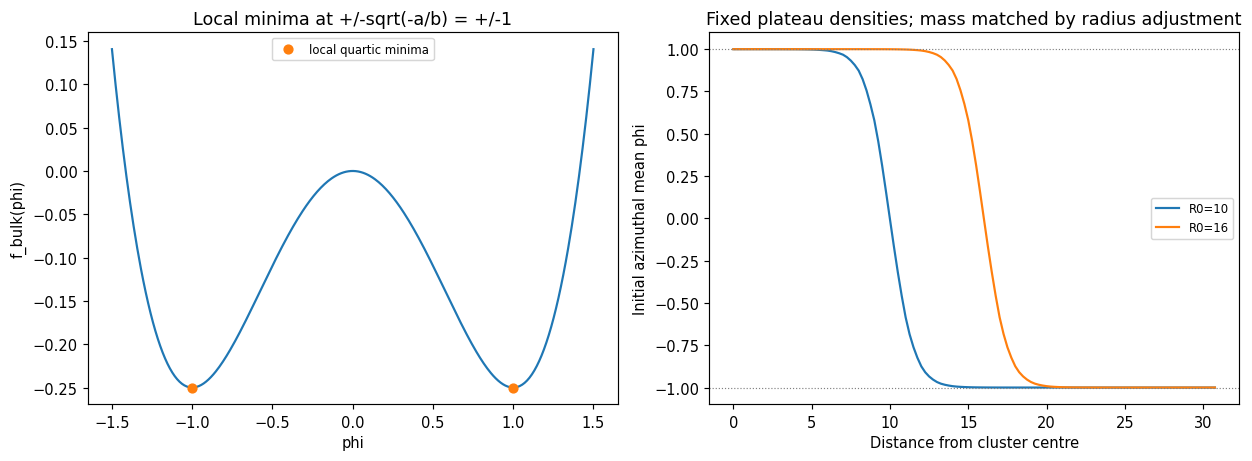

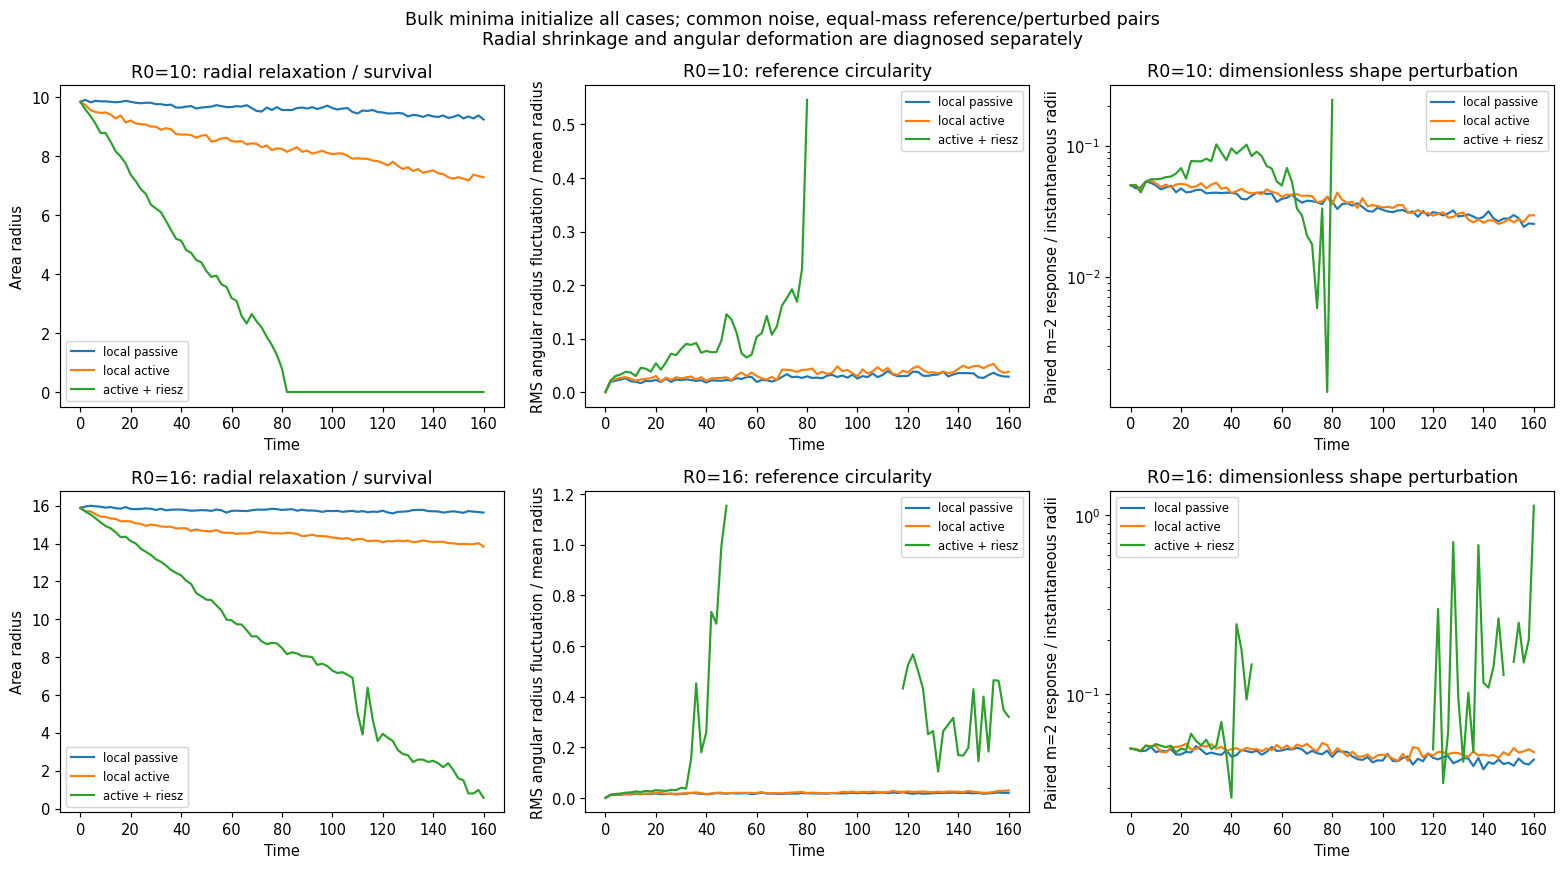

[{'case': 'local passive',
  'R0': 10.0,
  'relative shape fit': {'rate': -0.004139747963174447,
   'ci95': 0.0014435260534222437,
   'points': 21,
   'observable': 'paired interface mode normalized by each instantaneous mean radius',
   'interpretation': 'finite-time decay'},
  'reference': {'final_area_ratio': 0.9081967213114754,
   'final_components': 1,
   'breakup_in_last_quarter': False,
   'median_tail_relative_roughness': 0.032795200688027236,
   'circularity': 'approximately circular',
   'interpretation': 'single cluster survives this window'}},
 {'case': 'local active',
  'R0': 10.0,
  'relative shape fit': {'rate': -0.0015621989112612107,
   'ci95': 0.0018214100635877014,
   'points': 21,
   'observable': 'paired interface mode normalized by each instantaneous mean radius',
   'interpretation': 'unresolved growth sign'},
  'reference': {'final_area_ratio': 0.5704918032786885,
   'final_components': 1,
   'breakup_in_last_quarter': False,
   'median_tail_relative_roughness':

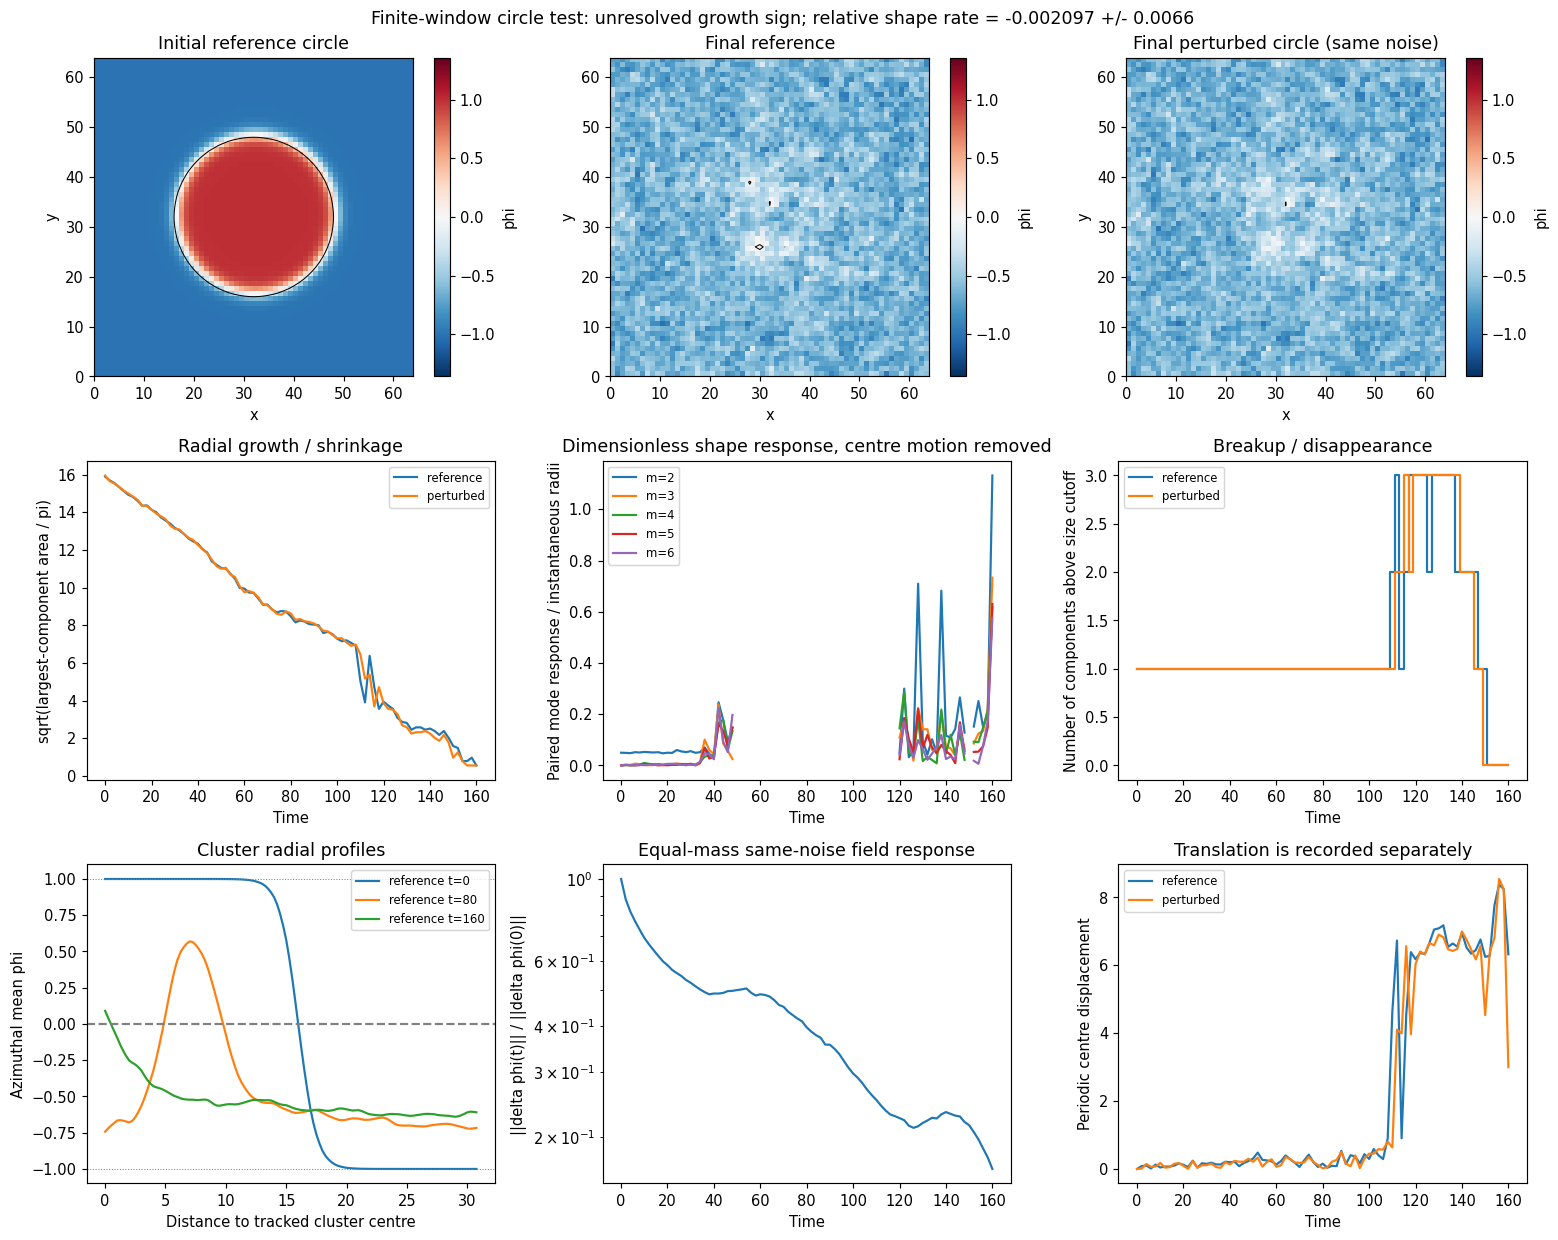

In [5]:
fig_init=plot_circle_initialization(circle_suite,circle_p,CIRCLE_OUTPUT)
plt.show()
fig_comparison=plot_circle_comparison(circle_suite,CIRCLE_OUTPUT)
plt.show()
display([{'case':r['name'],'R0':r['radius'],
    'relative shape fit':r['report']['fit'],'reference':r['report']['survival'][0]}
    for r in circle_suite])
save_circle_report(circle_report, CIRCLE_OUTPUT/'stability.json')
fig_circle = plot_circle_stability(circle_ref, circle_pert, circle_report, CIRCLE_OUTPUT)
plt.show()


## 9. 중앙 wall의 finite-time stability

Circle 실험과 함께 **flat wall / sinusoidally perturbed wall**을 비교한다.
현재 FFT solver는 양방향 periodic이다. 따라서 x=L/2의 중앙 rising wall과 x=0의
falling companion wall을 함께 초기화한다. 두 상을 연결하는 wall 하나만 두고 periodic
경계의 불연속을 숨기지 않는다. 이 section의 기준 mean은 두 상을 절반씩 둔 약 0이다.

초기 phi plateau는 bulk 최소점 $\pm\sqrt{-a/b}$, 기본값 **+1 / -1**이다.
중앙 wall에 $h(y)=A\cos(2\pi m y/L)$를 주고 companion은 처음에는 평평하게 둔다.
`PERTURBATION='bend'`는 두 wall을 같은 방향으로, `'thickness'`는 반대로 변형한다.
질량은 중앙 wall의 상수 위치를 root solve하여 맞추며 phi 전체를 shift하지 않는다.
동일 noise를 쓰는 flat/perturbed pair를 Euler–Maruyama로 적분하고 EP는 midpoint로 계산한다.

- 양쪽 계면의 높이 $h(y,t)$와 Fourier mode response $\delta h_m(t)$
- m=0 translation, 평균 slab 두께 변화, 계면 roughness를 구분
- 중앙/companion 및 centre-bending / thickness mode를 함께 저장
- 추가 crossing·overhang·계면 소실을 검출하고 graph가 깨지면 높이와 성장률 해석을 중단

Local passive, local active, 현재 active+kernel의 세 경우를 명시적으로 비교한다.
Fit은 초기 작은 perturbation 구간의 $\log|\delta h_m|$ slope이며, 시간 상관이 있는
한 seed의 finite-window 진단이다. 안정성 경계나 asymptotic dispersion relation을 확정하지 않는다.


In [3]:
from lramb.wall import WallSpec,wall_initial,wall_observables
from lramb.wall_experiments import (run_wall_suite,plot_wall_initialization,
    plot_wall_comparison,plot_wall_stability)
WALL_MODE=2
WALL_AMPLITUDE=1.0
WALL_PERTURBATION='central'  # central only / bend / thickness
WALL_STEPS=16_000
WALL_FIT_UNTIL=40.0
WALL_SIMULATION=backend_options('torch',device='auto',dtype='float64')
WALL_OUTPUT=OUTPUT/'wall_bulk_minima'
WALL_CONTROL_OUTPUT=ROOT/'results'/'wall_controls_bulk_minima'
wall_p=replace(p,seed=p.seed+200)
wall_spec=WallSpec.from_bulk(wall_p,mode=WALL_MODE,amplitude=WALL_AMPLITUDE,
                            perturbation=WALL_PERTURBATION)
wall_flat=wall_initial(wall_p,wall_spec)
wall_bent=wall_initial(wall_p,wall_spec,perturbed=True,mean=wall_flat.mean())
wall_initial_obs=wall_observables(np.stack([wall_flat,wall_bent]),p.dx,wall_spec)
display(asdict(wall_spec))
print('Periodic wall locations: central L/2, companion at x=0')
print('Mean flat / perturbed:',wall_flat.mean(),wall_bent.mean())
print('Initial graph fractions:',wall_initial_obs['graph_fraction'])
print('Measured initial central mode amplitude:',
      2*abs(wall_initial_obs['coefficients'][1,0,WALL_MODE]))


{'width': 1.4142135623730951,
 'phi_positive': 1.0,
 'phi_negative': -1.0,
 'centre': None,
 'amplitude': 1.0,
 'mode': 2,
 'perturbation': 'central',
 'graph_fraction': 0.95,
 'track_modes': 8}

Periodic wall locations: central L/2, companion at x=0
Mean flat / perturbed: -1.734723475976807e-18 -1.474514954580286e-17
Initial graph fractions: [1. 1.]
Measured initial central mode amplitude: 0.9925847357326649


In [4]:
wall_suite=run_wall_suite(wall_p,kernel,spec=wall_spec,
    output=WALL_OUTPUT,control_output=WALL_CONTROL_OUTPUT,steps=WALL_STEPS,
    sample_every=SAMPLE_EVERY,frame_every=FRAME_EVERY,blocks=BLOCKS,
    fit_until=WALL_FIT_UNTIL,multiplier=CUSTOM_MULTIPLIER,
    simulation=WALL_SIMULATION,reuse_cache=REUSE_CACHE)
display([{'case':r['name'],
    'reference mean':float(r['reference'].mass[0]),
    'paired initial mass mismatch':float(abs(r['reference'].mass[0]-r['perturbed'].mass[0])),
    'mass drift':float(np.ptp(r['reference'].mass)),
    'mode fit':r['report']['fit'],'interface survival':r['report']['survival']}
    for r in wall_suite])
wall_actual=next(r for r in wall_suite if r['control'] is None)


Wall local passive: matching cache
Wall local active: matching cache
Wall active + riesz: matching cache


[{'case': 'local passive',
  'reference mean': 1.734723475976807e-18,
  'paired initial mass mismatch': 1.7780915628762273e-17,
  'mass drift': 1.0842021724855044e-17,
  'mode fit': {'rate': -0.004676664558099877,
   'ci95': 0.0016702509310995073,
   'points': 21,
   'mode': 2,
   'wave_number': 0.19634954084936207,
   'observable': 'paired central-wall displacement Fourier amplitude; m=0 translation removed',
   'interpretation': 'finite-time decay'},
  'interface survival': [{'final_graph_fraction': 1.0,
    'first_graph_loss_time': None,
    'final_mean_slab_width': 32.08487363021413,
    'final_central_roughness': 0.2830084746301427,
    'interpretation': 'two resolved interface graphs survive this window'},
   {'final_graph_fraction': 1.0,
    'first_graph_loss_time': None,
    'final_mean_slab_width': 32.083484036389564,
    'final_central_roughness': 0.4380057846601467,
    'interpretation': 'two resolved interface graphs survive this window'}]},
 {'case': 'local active',
  'ref

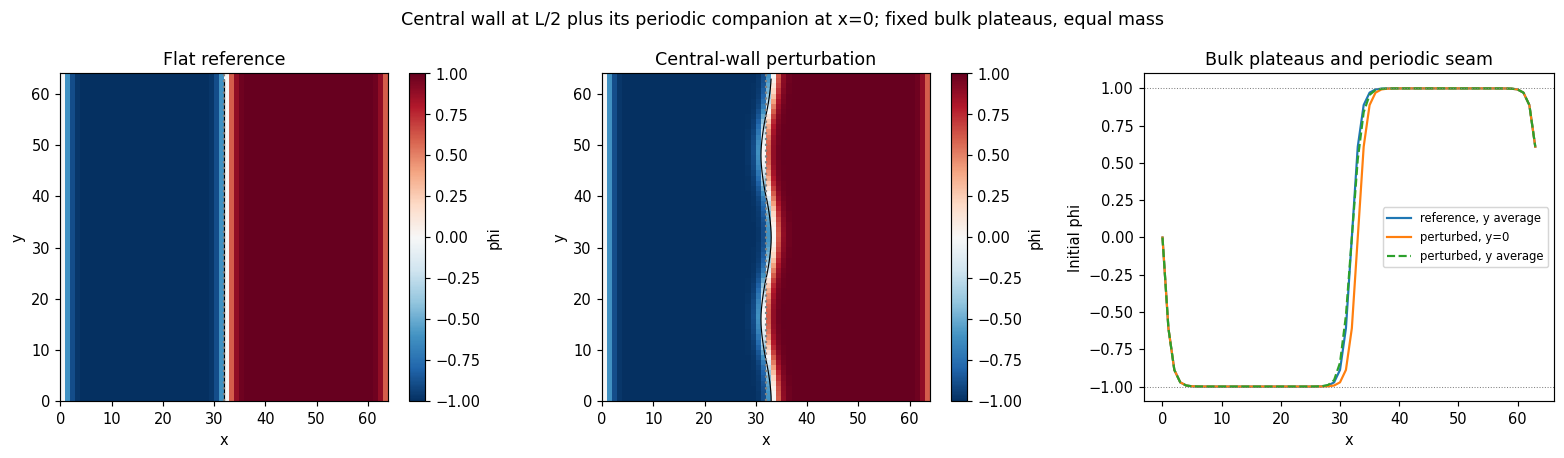

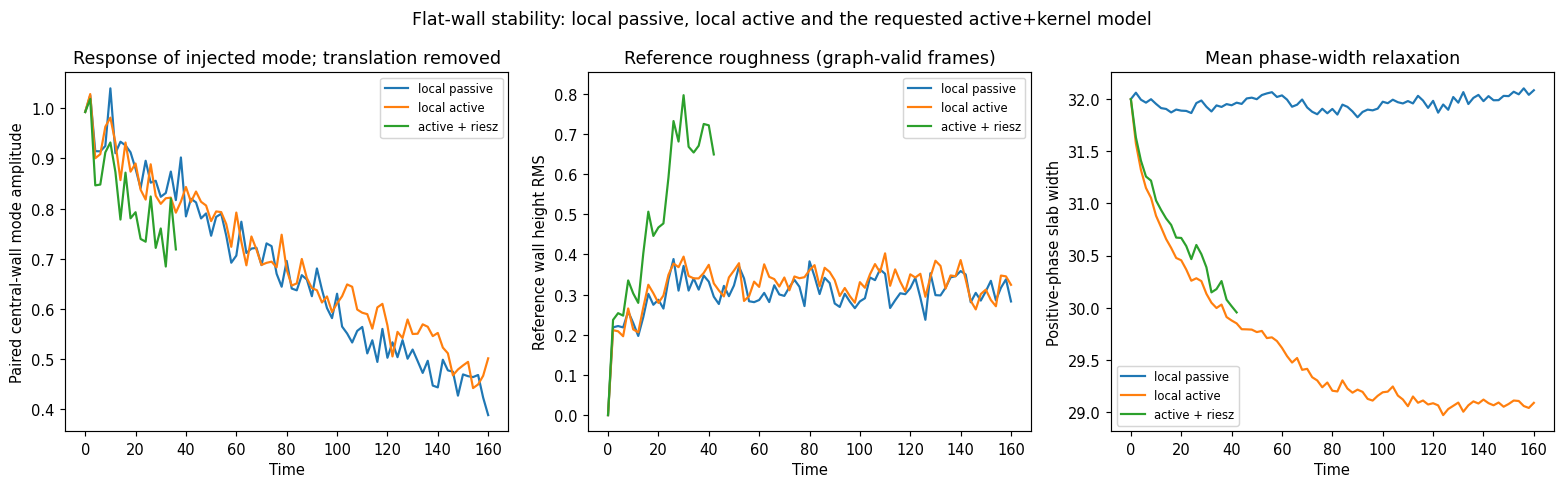

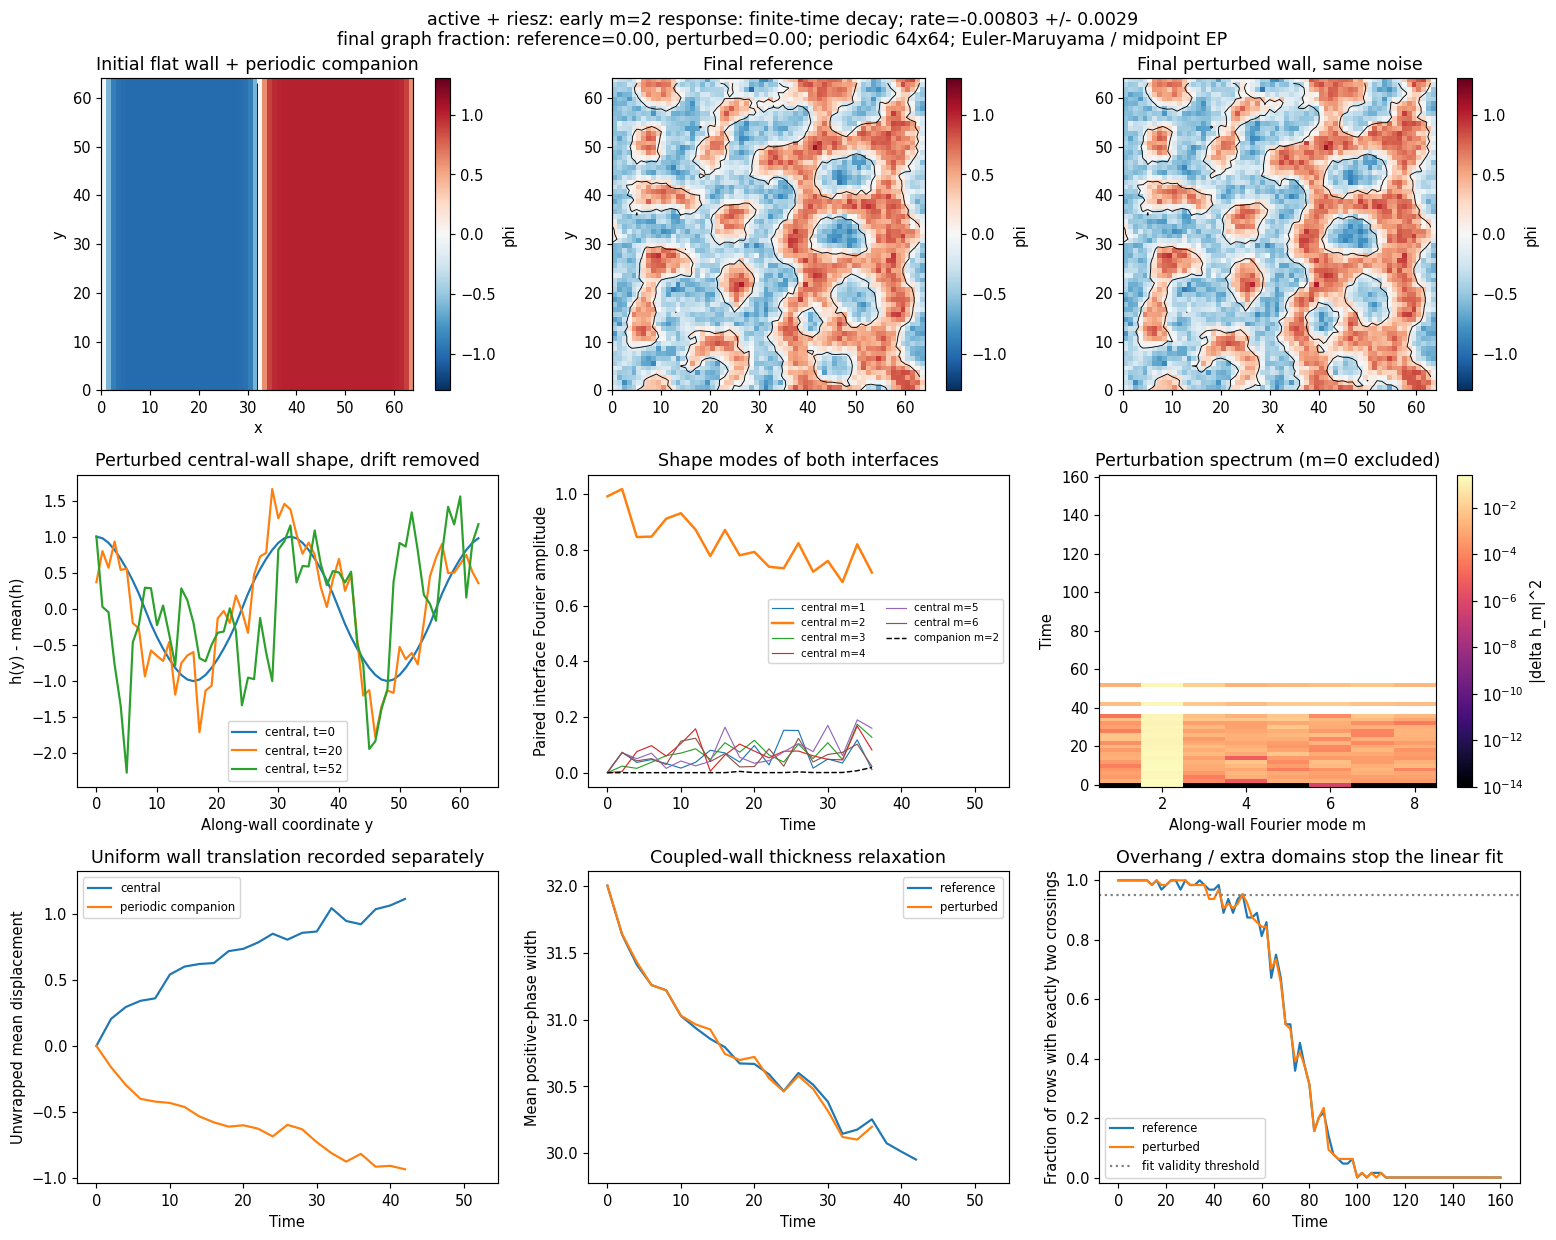

In [5]:
fig_wall_init=plot_wall_initialization(wall_suite,WALL_OUTPUT)
plt.show()
fig_wall_comparison=plot_wall_comparison(wall_suite,WALL_OUTPUT)
plt.show()
fig_wall=plot_wall_stability(wall_actual,WALL_OUTPUT)
plt.show()


## 저장 결과와 재현

`results/riesz/`에 trajectory NPZ, 커널/진단/EP/structure/spectrum PNG, profile GIF, phi_distance_decomposition NPZ, stationarity JSON이 저장된다. `circle_bulk_minima/`에는 수정한 초기 조건의 radius별 원형/변형 trajectory와 초기값/비교/stability PNG/JSON이 저장된다. Local control은 `results/circle_controls_bulk_minima/`를 공유한다. `wall_bulk_minima/`에는 flat/perturbed wall의 trajectory와 초기값/성장률/계면 spectrum PNG/NPZ/JSON이 저장된다. NPZ에는 seed, 적분 간격, sampling 간격, 모델 파라미터와 cache signature가 포함된다. seed를 바꾸어 독립 실험을 하고, $dt$를 절반으로 줄이면 step 수를 두 배로 늘려 동일한 물리 시간과 sampling interval을 유지한다.

참고: [Wittkowski et al., AMB (2014)](https://www.nature.com/articles/ncomms5351), [Nardini et al., field entropy (2017)](https://arxiv.org/abs/1610.06112), [Lim & Teo, multivariate Linnik (2009)](https://arxiv.org/abs/0903.5344), [Stinga, fractional Laplacian/semigroups (2018)](https://arxiv.org/abs/1808.05159).